In [ ]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Set seeds so that the splits and training are repeatable. same as in the augmentation too
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

#RUN PROJECT ON THE SAME LAYOUT AS SEEN IN MY LAYOUT
PROJECT_ROOT = Path.cwd()
BALANCED_DATASET = PROJECT_ROOT / "datasets" / "aptos_512_clahe_balanced"
TRAIN_DIR = BALANCED_DATASET / "train"
VAL_DIR = BALANCED_DATASET / "validation"
TEST_DIR = BALANCED_DATASET / "test"
OUTPUT_DIR = PROJECT_ROOT / "artefacts" / "cnn_baseline"
#creates outputs and store them here
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

#using full img size and dividing to batches
IMAGE_SIZE = (512, 512)
BATCH_SIZE = 4
EPOCHS = 30
NUM_CLASSES = 5
AUTOTUNE = tf.data.AUTOTUNE


## Dataset sizes and class counts in prepared folders

In [2]:
# Read the saved labels from the prepared train, validation, and test folders.
train_clahe = pd.read_csv(TRAIN_DIR / "labels.csv")
val_clahe = pd.read_csv(VAL_DIR / "labels.csv")
test_clahe = pd.read_csv(TEST_DIR / "labels.csv")

print("Training counts (balanced):")
print(train_clahe["diagnosis"].value_counts().sort_index())
print("\nValidation counts (original images):")
print(val_clahe["diagnosis"].value_counts().sort_index())
print("\nTest counts (original images):")
print(test_clahe["diagnosis"].value_counts().sort_index())


Training counts (balanced):
diagnosis
0    1263
1    1263
2    1263
3    1263
4    1263
Name: count, dtype: int64

Validation counts (original images):
diagnosis
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64

Test counts (original images):
diagnosis
0    271
1     56
2    150
3     29
4     44
Name: count, dtype: int64


## Shared CNN and image input functions instead of rewriting

In [3]:
#10 layered cnn: rescaling, 3 conv layers, 4 pooling and dropout and output
def make_model():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(*IMAGE_SIZE, 3)),
        #scale the data to 0-1
        tf.keras.layers.Rescaling(1 / 255.0),
        tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        #global pooling and results to make model a bit smaller
        tf.keras.layers.GlobalAveragePooling2D(),
        #dropout to avoid overfiiting
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

#batching images so pc doesnt explode
def decode_image(path, label):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    #using original img size
    image = tf.image.resize(image, IMAGE_SIZE)
    return image, tf.cast(label, tf.int32)


def make_dataset(frame, image_dir, training=False):
    paths = [str(image_dir / f"{image_id}.png") for image_id in frame["id_code"]]
    labels = frame["diagnosis"].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        #Shuffle training
        dataset = dataset.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return dataset.map(decode_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

#early stopping عشان الجتهز ميضربش
def make_early_stopping():
    return tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )


## Load the prepared train, validation, and test folders

In [ ]:
# Use the split folders created by the augmentation notebook; no new split is made here.
#MUST RUN THE AYGMENTATION FILE
train_ds_clahe = make_dataset(train_clahe, TRAIN_DIR / "images", training=True)
val_ds_clahe = make_dataset(val_clahe, VAL_DIR / "images")
test_ds_clahe = make_dataset(test_clahe, TEST_DIR / "images")


## Train the CNN

In [ ]:
#traun
model_clahe = make_model()
history_clahe = model_clahe.fit(
    train_ds_clahe,
    validation_data=val_ds_clahe,
    epochs=EPOCHS,
    callbacks=[make_early_stopping()],
    verbose=1,
)
model_clahe.save(OUTPUT_DIR / "aptos_cnn_512_clahe.keras")


Epoch 1/30
1579/1579 ━━━━━━━━━━━━━━━━━━━━ 223s 140ms/step - accuracy: 0.3135 - loss: 1.4538 - val_accuracy: 0.5964 - val_loss: 1.0489
Epoch 2/30
1579/1579 ━━━━━━━━━━━━━━━━━━━━ 207s 131ms/step - accuracy: 0.4193 - loss: 1.2701 - val_accuracy: 0.6782 - val_loss: 0.9269
Epoch 3/30
1579/1579 ━━━━━━━━━━━━━━━━━━━━ 214s 136ms/step - accuracy: 0.4567 - loss: 1.2165 - val_accuracy: 0.6945 - val_loss: 0.8943
Epoch 4/30
1579/1579 ━━━━━━━━━━━━━━━━━━━━ 229s 145ms/step - accuracy: 0.4814 - loss: 1.1712 - val_accuracy: 0.7145 - val_loss: 0.8327
Epoch 5/30
1579/1579 ━━━━━━━━━━━━━━━━━━━━ 207s 131ms/step - accuracy: 0.4909 - loss: 1.1547 - val_accuracy: 0.7182 - val_loss: 0.8237
Epoch 6/30
1579/1579 ━━━━━━━━━━━━━━━━━━━━ 209s 132ms/step - accuracy: 0.5004 - loss: 1.1370 - val_accuracy: 0.7145 - val_loss: 0.8106
Epoch 7/30
1579/1579 ━━━━━━━━━━━━━━━━━━━━ 214s 136ms/step - accuracy: 0.4998 - loss: 1.1307 - val_accuracy: 0.7182 - val_loss: 0.8247
Epoch 8/30
1579/1579 ━━━━━━━━━━━━━━━━━━━━ 214s 135ms/step - ac

## evaluation

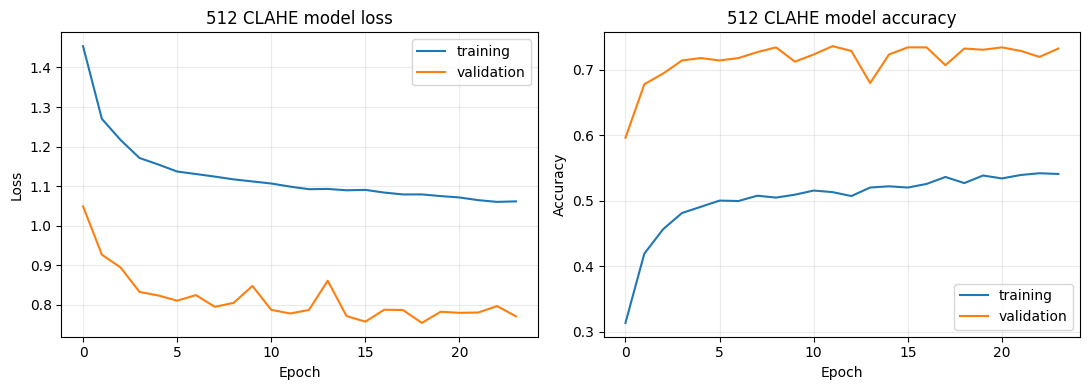

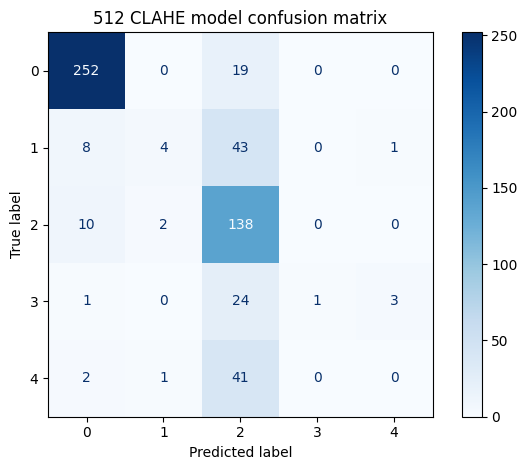

              precision    recall  f1-score   support

     Grade 0       0.92      0.93      0.93       271
     Grade 1       0.57      0.07      0.13        56
     Grade 2       0.52      0.92      0.67       150
     Grade 3       1.00      0.03      0.07        29
     Grade 4       0.00      0.00      0.00        44

    accuracy                           0.72       550
   macro avg       0.60      0.39      0.36       550
weighted avg       0.71      0.72      0.65       550



In [8]:
#predict vs actual on clahe
y_true_clahe = test_clahe["diagnosis"].to_numpy(dtype=np.int32)
y_pred_clahe = model_clahe.predict(test_ds_clahe, verbose=0).argmax(axis=1)
precision_clahe, recall_clahe, f1_clahe, support_clahe = precision_recall_fscore_support(
    y_true_clahe, y_pred_clahe, labels=list(range(NUM_CLASSES)), zero_division=0
)
confusion_clahe = confusion_matrix(y_true_clahe, y_pred_clahe, labels=list(range(NUM_CLASSES)))

#per grade accuracy


#plot training validation loss
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_clahe.history["loss"], label="training")
axes[0].plot(history_clahe.history["val_loss"], label="validation")
axes[0].set(title="512 CLAHE model loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(history_clahe.history["accuracy"], label="training")
axes[1].plot(history_clahe.history["val_accuracy"], label="validation")
axes[1].set(title="512 CLAHE model accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "training_curves_512_clahe.png", dpi=200, bbox_inches="tight")
plt.show()

#confusuin matrix
confusion_plot = ConfusionMatrixDisplay(
    confusion_matrix=confusion_clahe, display_labels=range(NUM_CLASSES)
).plot(cmap="Blues", values_format="d")
plt.title("512 CLAHE model confusion matrix")
plt.tight_layout()
confusion_plot.figure_.savefig(
    OUTPUT_DIR / "confusion_matrix_512_clahe.png", dpi=200, bbox_inches="tight"
)
plt.show()

from sklearn.metrics import classification_report

print(classification_report(
    y_true_clahe,
    y_pred_clahe,
    labels=[0, 1, 2, 3, 4],
    target_names=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"],
    zero_division=0
))

In [1]:
# Reload the saved baseline CNN and report its trainable parameter count.
from pathlib import Path
import numpy as np
import tensorflow as tf

cnn_model_candidates = [
    Path('artefacts/cnn_baseline/aptos_cnn_512_clahe.keras'),
    Path('../artefacts/cnn_baseline/aptos_cnn_512_clahe.keras'),
]
cnn_model_path = next((path.resolve() for path in cnn_model_candidates if path.is_file()), None)
if cnn_model_path is None:
    raise FileNotFoundError('Could not find the saved CNN model at artefacts/cnn_baseline/aptos_cnn_512_clahe.keras.')

reloaded_cnn = tf.keras.models.load_model(cnn_model_path, compile=False)
print(f'Loaded CNN model: {cnn_model_path}')
reloaded_cnn.summary()

print('Trainable parameters by layer:')
for layer in reloaded_cnn.layers:
    layer_trainable_params = sum(int(np.prod(weight.shape)) for weight in layer.trainable_weights)
    if layer_trainable_params:
        print(f'  {layer.name}: {layer_trainable_params:,}')
trainable_parameter_count = sum(int(np.prod(weight.shape)) for weight in reloaded_cnn.trainable_weights)
non_trainable_parameter_count = sum(int(np.prod(weight.shape)) for weight in reloaded_cnn.non_trainable_weights)
print(f'Total trainable parameters: {trainable_parameter_count:,}')
print(f'Total non-trainable parameters: {non_trainable_parameter_count:,}')


Loaded CNN model: D:\omar\SIC\grad_project\artefacts\cnn_baseline\aptos_cnn_512_clahe.keras


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 512, 512, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 512, 512, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 256, 256, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 256, 256, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,909 (93.39 KB)

 Trainable params: 23,909 (93.39 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters by layer:
  conv2d: 448
  conv2d_1: 4,640
  conv2d_2: 18,496
  dense: 325
Total trainable parameters: 23,909
Total non-trainable parameters: 0


69/69 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step
ROC curve saved to: D:\omar\SIC\grad_project\artefacts\cnn_baseline\cnn_roc_curve.png


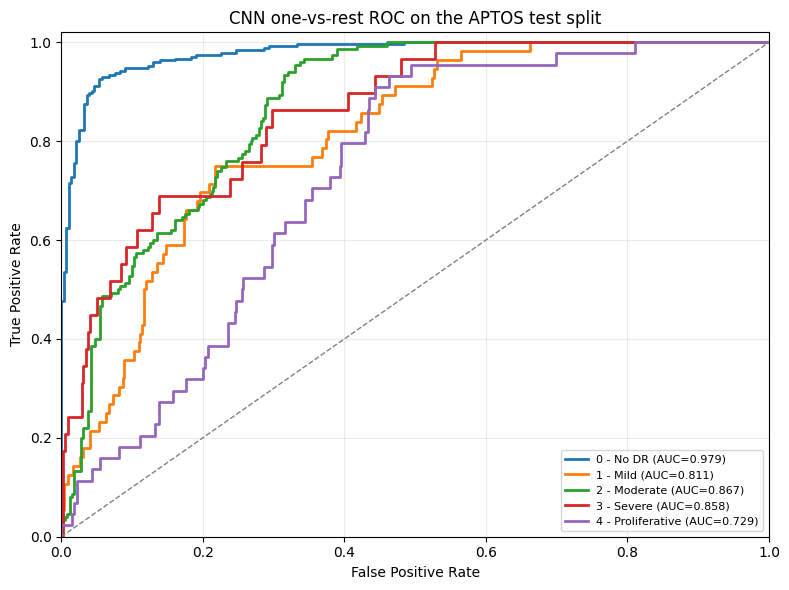

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

#roc curve bc we forgot it

model_candidates = [
        Path('artefacts/cnn_baseline/aptos_cnn_512_clahe.keras'),
        Path('../artefacts/cnn_baseline/aptos_cnn_512_clahe.keras')
]
roc_model_path = next((p.resolve() for p in model_candidates if p.is_file()), None)
if roc_model_path is None:
    raise FileNotFoundError('Could not find the saved CNN model.')

test_split_candidates = [
    Path('datasets/aptos_512_clahe_balanced/test'),
    Path('Dataset/aptos_512_clahe_balanced/test'),
    Path('../datasets/aptos_512_clahe_balanced/test'),
    Path('../Dataset/aptos_512_clahe_balanced/test'),
]
roc_test_root = next((p.resolve() for p in test_split_candidates if (p / 'labels.csv').is_file()), None)
if roc_test_root is None:
    raise FileNotFoundError('Could not find the balanced test split with labels.csv.')
roc_frame = pd.read_csv(roc_test_root / 'labels.csv')
roc_y_true = roc_frame['diagnosis'].to_numpy(dtype=np.int32)
class_ids = np.arange(5)
roc_y_one_hot = label_binarize(roc_y_true, classes=class_ids)
class_names = ['0 - No DR', '1 - Mild', '2 - Moderate', '3 - Severe', '4 - Proliferative']

roc_model = tf.keras.models.load_model(roc_model_path, compile=False)
input_size = tuple(roc_model.input_shape[1:3])
image_paths = roc_frame['id_code'].map(
    lambda image_id: str(roc_test_root / 'images' / f'{image_id}.png')
).to_numpy(dtype=str)
missing = [p for p in image_paths if not os.path.isfile(p)]
if missing:
    raise FileNotFoundError(f'Missing test image: {missing[0]}')

def _decode_roc_image(path):
    image = tf.io.decode_png(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, input_size, method='lanczos3')
    image = tf.cast(image, tf.float32)
    return image

roc_test_ds = (tf.data.Dataset.from_tensor_slices(image_paths)
               .map(_decode_roc_image, num_parallel_calls=tf.data.AUTOTUNE)
               .batch(8).prefetch(tf.data.AUTOTUNE))
roc_scores = roc_model.predict(roc_test_ds, verbose=1)

fig, ax = plt.subplots(figsize=(8, 6))
for class_index, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(roc_y_one_hot[:, class_index], roc_scores[:, class_index])
    class_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=2, label=f'{class_name} (AUC={class_auc:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1)
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='False Positive Rate', ylabel='True Positive Rate',
       title='CNN one-vs-rest ROC on the APTOS test split')
ax.grid(alpha=0.25)
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
roc_output_path = roc_model_path.parent / 'cnn_roc_curve.png'
fig.savefig(roc_output_path, dpi=200, bbox_inches='tight')
print(f'ROC curve saved to: {roc_output_path}')
plt.show()
